<a href="https://colab.research.google.com/github/SkyWarLimit/PemMes_17/blob/main/JS08/JS08_Tugas2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

# Gunakan ini untuk sklearn >= 1.3
from sklearn.cluster import HDBSCAN
# Jika error (versi lama), gunakan modul eksternal:
# import hdbscan
# lalu ganti pemanggilan fungsi di sel berikutnya dengan hdbscan.HDBSCAN(...)

# Memuat dataset Iris
iris = load_iris()
X_iris = iris.data
y_iris = iris.target # Label asli (hanya digunakan untuk analisis nanti)

In [2]:
# Membangun dan melatih model HDBSCAN
# min_cluster_size menentukan batas minimum sampel untuk membentuk satu klaster
hdb = HDBSCAN(min_cluster_size=5)
hdb_labels = hdb.fit_predict(X_iris)

In [3]:
# Label -1 merepresentasikan noise dalam HDBSCAN
# Kita hitung jumlah klaster (mengabaikan -1)
jumlah_cluster = len(set(hdb_labels)) - (1 if -1 in hdb_labels else 0)

# Menghitung seberapa banyak titik data yang dianggap sebagai noise
banyaknya_noise = list(hdb_labels).count(-1)

print(f"Jumlah cluster yang terbentuk : {jumlah_cluster}")
print(f"Banyaknya noise (titik outlier): {banyaknya_noise}")

Jumlah cluster yang terbentuk : 2
Banyaknya noise (titik outlier): 0


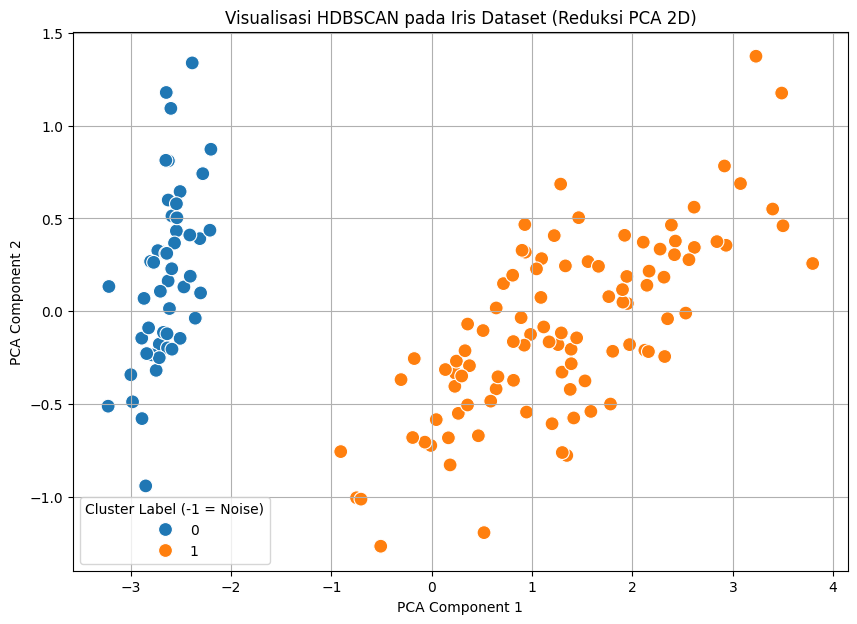

In [4]:
# Reduksi dimensi menggunakan PCA (dari 4 fitur iris ke 2 dimensi)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_iris)

plt.figure(figsize=(10, 7))
# Scatter plot untuk PCA, diwarnai sesuai label prediksi HDBSCAN
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=hdb_labels, palette='tab10', s=100)
plt.title('Visualisasi HDBSCAN pada Iris Dataset (Reduksi PCA 2D)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(title='Cluster Label (-1 = Noise)')
plt.grid(True)
plt.show()

In [7]:
# Menggunakan metrik eksternal Adjusted Rand Index (ARI)
# ARI mengukur kemiripan antara label asli dengan klaster prediksi
ari_score = adjusted_rand_score(y_iris, hdb_labels)

print(f"Adjusted Rand Index (ARI) score: {ari_score:.4f}")
print("-" * 50)
print("ANALISIS SINGKAT:")
print("1. Hasil klasterisasi HDBSCAN cukup mendekati namun tidak 100% cocok dengan label asli Iris.")
print("2. Dataset Iris secara historis memiliki 3 kelas asli, di mana kelas 'Setosa' sangat terpisah dengan jelas, "
      "sedangkan kelas 'Versicolor' dan 'Virginica' sedikit tumpang tindih.")
print("3. Algoritma berbasis densitas seperti HDBSCAN cenderung sangat akurat memisahkan klaster Setosa yang terisolasi. "
      "Namun, untuk dua kelas lainnya yang saling beririsan densitasnya, HDBSCAN seringkali menganggap irisan tersebut "
      "sebagai satu klaster besar yang sama atau memasukkan area tepinya ke dalam titik 'Noise' (label -1).")
print("4. Kesimpulannya, HDBSCAN menemukan struktur alami data (berdasarkan kepadatan), meskipun struktur "
      "tersebut bisa saja membentuk 2 klaster besar alih-alih 3 seperti pada label aslinya.")

Adjusted Rand Index (ARI) score: 0.5681
--------------------------------------------------
ANALISIS SINGKAT:
1. Hasil klasterisasi HDBSCAN cukup mendekati namun tidak 100% cocok dengan label asli Iris.
2. Dataset Iris secara historis memiliki 3 kelas asli, di mana kelas 'Setosa' sangat terpisah dengan jelas, sedangkan kelas 'Versicolor' dan 'Virginica' sedikit tumpang tindih.
3. Algoritma berbasis densitas seperti HDBSCAN cenderung sangat akurat memisahkan klaster Setosa yang terisolasi. Namun, untuk dua kelas lainnya yang saling beririsan densitasnya, HDBSCAN seringkali menganggap irisan tersebut sebagai satu klaster besar yang sama atau memasukkan area tepinya ke dalam titik 'Noise' (label -1).
4. Kesimpulannya, HDBSCAN menemukan struktur alami data (berdasarkan kepadatan), meskipun struktur tersebut bisa saja membentuk 2 klaster besar alih-alih 3 seperti pada label aslinya.
